In [2]:
import pandas as pd 
import os
import pymysql
import xml.etree.ElementTree as ET
import csv
from pathlib import Path
import matplotlib.pyplot as plt

In [28]:
# This script is used to insert the file name and file path of genomic data into the database.
# (db = tgca_gbm, table = raw_file_name_genomic_data)
conn = pymysql.connect(host='localhost', user='mmc', password='root', db='tcga_gbm')

def insert_file_records(conn, table_name, file_records):
    """
    Insert a list of (file_name, file_path) tuples into the specified table.
    """
    with conn.cursor() as cursor:
        sql = f"INSERT INTO {table_name} (file_name, file_path) VALUES (%s, %s)"
        cursor.executemany(sql, file_records)
    conn.commit()

def collect_file_records(base_path, extension):
    records = []
    for root, dirs, files in os.walk(base_path):
        for file in files:
            if file.endswith(extension):
                records.append((file, os.path.join(root, file)))
    return records



In [29]:
# The insertion logic is handled by the insert_file_records function in the previous cell.
# Insert genomic data records
truncate_qry = "truncate table raw_file_name_genomic_data;"
conn.cursor().execute(truncate_qry)
genomic_data_path = "/home/licongcong/Desktop/TCGA/tcga-gbm/genomic_data"
genomic_records = collect_file_records(genomic_data_path, ".tsv")
insert_file_records(conn, "raw_file_name_genomic_data", genomic_records)



In [30]:
# Insert WSI file records
truncate_qry = "truncate table raw_file_name_WSI;"
conn.cursor().execute(truncate_qry)
wsi_data_path = "/home/licongcong/Desktop/TCGA/tcga-gbm/WSI_image"
wsi_records = collect_file_records(wsi_data_path, ".svs")
insert_file_records(conn, "raw_file_name_WSI", wsi_records)



In [31]:
# Insert clinic file records
truncate_qry = "truncate table raw_file_name_clinic;"
conn.cursor().execute(truncate_qry)
clinic_data_path = "/home/licongcong/Desktop/TCGA/tcga-gbm/clinical"
clinic_records = collect_file_records(clinic_data_path, ".xml")
insert_file_records(conn, "raw_file_name_clinic", clinic_records)

In [32]:
def extract_xml_data(file_path):
    """
    Extract patient_id and bcr_patient_uuid from a clinical XML file.
    """
    try:
        tree = ET.parse(file_path)
        root = tree.getroot()
        
        # Function to find element by local name, ignoring namespace
        def find_by_local_name(element, local_name):
            for elem in element.iter():
                if elem.tag.split('}')[-1] == local_name:  # Extract local name from {namespace}localname
                    return elem
            return None
        
        # Extract patient_id and bcr_patient_uuid using flexible search
        patient_id_elem = find_by_local_name(root, 'bcr_patient_barcode')
        bcr_patient_uuid_elem = find_by_local_name(root, 'bcr_patient_uuid')
        age_patient = find_by_local_name(root, 'age_at_initial_pathologic_diagnosis')
        gender = find_by_local_name(root, 'gender')
        vital_status = find_by_local_name(root, 'vital_status')
        therapy_type = find_by_local_name(root, 'therapy_type')

        
        result = {
            'patient_id': patient_id_elem.text if patient_id_elem is not None else None,
            'bcr_patient_uuid': bcr_patient_uuid_elem.text if bcr_patient_uuid_elem is not None else None,
            'age_patient': age_patient.text if age_patient is not None else None,
            'gender': gender.text if gender is not None else None,
            'vital_status': vital_status.text if vital_status is not None else None,
            'therapy_type': therapy_type.text if therapy_type is not None else None
        }
        
        return result
    except Exception as e:
        print(f"Error parsing {file_path}: {e}")
        import traceback
        traceback.print_exc()
        return {'patient_id': None, 'bcr_patient_uuid': None}
    
def insert_xml_data(conn, table_name, xml_records):

    """
    Insert extracted XML data into the specified table.
    """
    with conn.cursor() as cursor:
        sql = f"INSERT INTO {table_name} (patient_id, bcr_patient_uuid, age, gender, vital_status, therapy_type) VALUES (%s, %s, %s, %s, %s, %s)"
        cursor.executemany(sql, [(record['patient_id'], record['bcr_patient_uuid'], record['age_patient'], record['gender'], record['vital_status'], record['therapy_type']) for record in xml_records])
    conn.commit()


In [33]:
clinic_data_path = "/home/licongcong/Desktop/TCGA/tcga-gbm/clinical"
truncate_qry = f"truncate table raw_clinic_data;"
conn.cursor().execute(truncate_qry)
for root, dirs, files in os.walk(clinic_data_path):
    for file in files:
        if file.endswith(".xml"):
            xml_data = extract_xml_data(os.path.join(root, file))
            print(xml_data)
            insert_xml_data(conn, "raw_clinic_data", [xml_data])

{'patient_id': 'TCGA-28-5219', 'bcr_patient_uuid': '567a8bf1-3793-46bc-9943-16302df056ce', 'age_patient': '47', 'gender': 'FEMALE', 'vital_status': 'Alive', 'therapy_type': 'Chemotherapy'}
{'patient_id': 'TCGA-14-1829', 'bcr_patient_uuid': '47a4161c-9c61-48f5-b9bc-a6d1acad4e5a', 'age_patient': '57', 'gender': 'MALE', 'vital_status': 'Alive', 'therapy_type': 'Hormone Therapy'}
{'patient_id': 'TCGA-08-0353', 'bcr_patient_uuid': '872cb8e8-cd79-4c0b-9b54-5553b07a6ca6', 'age_patient': '58', 'gender': 'MALE', 'vital_status': 'Dead', 'therapy_type': 'Chemotherapy'}
{'patient_id': 'TCGA-19-2619', 'bcr_patient_uuid': 'f2de4316-026c-4c2d-b091-47bc0ec8612a', 'age_patient': '55', 'gender': 'FEMALE', 'vital_status': 'Alive', 'therapy_type': 'Chemotherapy'}
{'patient_id': 'TCGA-12-1088', 'bcr_patient_uuid': 'ac72738c-8b33-4f03-917c-86b114a2b9bd', 'age_patient': '53', 'gender': 'FEMALE', 'vital_status': 'Dead', 'therapy_type': 'Chemotherapy'}
{'patient_id': 'TCGA-76-6191', 'bcr_patient_uuid': '8c3b28

In [34]:
def load_gmt_save_csv(file_path, output_csv_path):
    # Load the GMT file
    with open(file_path, 'r') as f:
        gmt_data = f.readlines()

    # Process the GMT data and save to CSV
    with open(output_csv_path, 'w', newline='') as f:
        writer = csv.writer(f)
        for line in gmt_data:
            parts = line.strip().split('\t')
            pathway_name = parts[0]
            gene_list = parts[2:]  # Skip the first two columns (pathway name, description)
            writer.writerow([pathway_name, ','.join(gene_list)])

gmt_file_path = "/home/licongcong/Desktop/TCGA/tcga-gbm/Hallmark/h.all.v2023.2.Hs.symbols.gmt"
output_csv_path = "/home/licongcong/Desktop/TCGA/tcga-gbm/Hallmark/hallmark_pathways.csv"
load_gmt_save_csv(gmt_file_path,output_csv_path)

In [35]:
gmt_file_path = "/home/licongcong/Desktop/TCGA/tcga-gbm/Reactome/ReactomePathways.gmt"
output_csv_path = "/home/licongcong/Desktop/TCGA/tcga-gbm/Reactome/reactome_pathways.csv"
load_gmt_save_csv(gmt_file_path, output_csv_path)

In [36]:
tsv_file_path = "/home/licongcong/Desktop/TCGA/tcga-gbm/TCGA-GBM.star_fpkm.tsv"
df = pd.read_csv(tsv_file_path, sep='\t')
df.head(5)

,Ensembl_ID,TCGA-27-2521-01A,TCGA-19-1390-01A,TCGA-27-1830-01A,TCGA-32-1970-01A,TCGA-06-0190-01A,TCGA-06-0190-02A,TCGA-02-2486-01A,TCGA-14-0790-01B,TCGA-14-0789-01A,...,TCGA-27-2519-01A,TCGA-26-5134-01A,TCGA-06-0675-11A,TCGA-06-1804-01A,TCGA-14-1829-01A,TCGA-06-0184-01A,TCGA-32-2638-01A,TCGA-12-3652-01A,TCGA-28-5209-01A,TCGA-76-4925-01A
0,ENSG00000000003.15,1.426909,2.805313,4.428598,4.153141,4.379032,3.596136,5.085548,4.754107,4.043126,...,4.640656,4.086444,1.867303,4.005643,6.383022,4.959306,4.894658,5.284381,4.427097,4.494032
1,ENSG00000000005.6,0.458172,0.018777,0.229957,0.311038,0.113567,0.387583,0.227248,0.287236,0.026021,...,0.519341,0.256044,0.129217,0.132643,1.776567,0.187514,0.523361,0.145743,0.183709,0.153805
2,ENSG00000000419.13,5.099240,4.108767,4.489215,3.966818,4.574338,4.598276,4.963238,4.477813,3.893187,...,4.978132,4.257629,4.099413,4.334261,5.603582,4.553471,4.711776,5.248246,4.448683,5.568433
3,ENSG00000000457.14,1.582363,1.451963,1.493545,1.358284,1.248717,1.080044,1.458959,1.339479,1.207206,...,1.318288,1.571046,1.270469,1.317420,1.449112,1.236829,1.418298,1.048027,1.423740,1.506348
4,ENSG00000000460.17,1.170630,1.547845,1.053737,1.078268,1.569102,1.316841,0.924936,1.059286,0.744764,...,0.941557,1.498047,0.342669,0.954866,1.637147,0.961105,1.051302,1.373063,1.386590,1.385541


In [37]:
subset = df[['Ensembl_ID', 'TCGA-06-2561-01A']].values
subset

array([['ENSG00000000003.15', 3.806973587975431],
       ['ENSG00000000005.6', 0.0938305716351355],
       ['ENSG00000000419.13', 4.513610754632368],
       ...,
       ['ENSG00000288671.1', 0.0],
       ['ENSG00000288674.1', 0.0294175468350917],
       ['ENSG00000288675.1', 0.992115808035672]],
      shape=(60660, 2), dtype=object)

In [38]:
csv_file_path = "/home/licongcong/Desktop/TCGA/tcga-gbm/clean_genomic_data_202604161842.csv"
raw = pd.read_csv(csv_file_path, sep=',')
raw.head(5)
raw_df_pivot = raw.pivot(index='patient_id', columns='gene_name', values='fpkm_value')

FileNotFoundError: [Errno 2] No such file or directory: '/home/licongcong/Desktop/TCGA/tcga-gbm/clean_genomic_data_202604161842.csv'

In [ ]:
csv_file_path = "/home/licongcong/Desktop/TCGA/tcga-gbm/clean_genomic_data_202604161842.csv"

In [44]:
def change_plain_text_file_to_csv(text_file_path, csv_file_path, delimiter='\t'):
    with open(text_file_path, 'r') as txt_file:
        reader = csv.reader(txt_file, delimiter=delimiter)
        rows = list(reader)

    with open(csv_file_path, 'w', newline='') as csv_file:
        writer = csv.writer(csv_file)
        writer.writerows(rows)

    print(f"Converted '{text_file_path}' to '{csv_file_path}' using delimiter '{delimiter}'")

In [45]:
test_file_path = "/home/licongcong/Desktop/TCGA/tcga-gbm/TCGA.GBM.sampleMap_GBM_clinicalMatrix"
output_csv_path = "/home/licongcong/Desktop/TCGA/tcga-gbm/TCGA_GBM_clinicalMatrix.csv"
change_plain_text_file_to_csv(test_file_path, output_csv_path, delimiter='\t')

Converted '/home/licongcong/Desktop/TCGA/tcga-gbm/TCGA.GBM.sampleMap_GBM_clinicalMatrix' to '/home/licongcong/Desktop/TCGA/tcga-gbm/TCGA_GBM_clinicalMatrix.csv' using delimiter '	'


In [46]:
df_clinical = pd.read_csv(output_csv_path)
# print(df_clinical.columns)
df_clinical_subset = df_clinical[['sampleID', 'CDE_DxAge', 'CDE_survival_time', 'CDE_vital_status', '_INTEGRATION', '_PATIENT', '_primary_site',
                                  'bcr_patient_barcode', 'bcr_patient_uuid', 'days_to_death', 'days_to_last_followup', 'days_to_new_tumor_event_after_initial_treatment',
                                  'gender','vital_status', 'year_of_initial_pathologic_diagnosis']]

df_clinical_subset['CDE_survival_month'] = (
    df_clinical_subset['CDE_survival_time'] / 30.0
)

df_clinical_subset = df_clinical_subset.rename(
    columns={
        'CDE_survival_time': 'CDE_survival_days',
        'CDE_survival_month': 'CDE_survival_time'
    }
)

df_clinical_subset.head(5)

/tmp/ipykernel_407144/1079583424.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clinical_subset['CDE_survival_month'] = (


,sampleID,CDE_DxAge,CDE_survival_days,CDE_vital_status,_INTEGRATION,_PATIENT,_primary_site,bcr_patient_barcode,bcr_patient_uuid,days_to_death,days_to_last_followup,days_to_new_tumor_event_after_initial_treatment,gender,vital_status,year_of_initial_pathologic_diagnosis,CDE_survival_time
0,TCGA-02-0001-01,44.30,353.0,DECEASED,TCGA-02-0001-01,TCGA-02-0001,Brain,TCGA-02-0001,30a1fe5e-5b12-472c-aa86-c2db8167ab23,358,279.0,137,FEMALE,DECEASED,2002.0,11.766667
1,TCGA-02-0002-01,NaN,NaN,NaN,TCGA-02-0002-01,TCGA-02-0002,Brain,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,TCGA-02-0003-01,50.21,144.0,DECEASED,TCGA-02-0003-01,TCGA-02-0003,Brain,TCGA-02-0003,df3c1d61-79c1-43e9-971a-8029497ffeab,144,144.0,40,MALE,DECEASED,2003.0,4.800000
3,TCGA-02-0004-01,59.18,345.0,DECEASED,TCGA-02-0004-01,TCGA-02-0004,Brain,TCGA-02-0004,3ac8f759-2df0-4ef5-913f-ce05b8dd8937,345,345.0,314,MALE,DECEASED,2002.0,11.500000
4,TCGA-02-0006-01,56.17,558.0,DECEASED,TCGA-02-0006-01,TCGA-02-0006,Brain,TCGA-02-0006,98714d95-b62e-4f34-9cd1-91542da463eb,558,558.0,302,FEMALE,DECEASED,2002.0,18.600000


In [47]:
clean_clinic_data_csv_path = "/home/licongcong/Desktop/TCGA/tcga-gbm/clean_clinic_data.csv"
df_clinical_subset.to_csv(clean_clinic_data_csv_path, index=False)

In [80]:
import pandas as pd
from sqlalchemy import create_engine

# CSV file path
csv_file = "../result/merge_df.csv"

# Table name
table_name = "analysis_table"

# MySQL connection information
host = "localhost"
user = "mmc"
password = "root"
database = "tcga_gbm"

# Read CSV file
df = pd.read_csv(csv_file)

# Select only specific columns
selected_columns = [
    "__label",
    "CDE_survival_time"
]

# Keep only selected columns
df_selected = df[selected_columns]

# Create SQLAlchemy engine
engine = create_engine(
    f"mysql+pymysql://{user}:{password}@{host}/{database}"
)

# Save selected columns into MySQL table
df_selected.to_sql(
    name=table_name,
    con=engine,
    if_exists='replace',   # replace table if exists
    index=False
)

print("Selected CSV columns successfully saved to MySQL database!")

Selected CSV columns successfully saved to MySQL database!


In [75]:
from pathlib import Path
from types import SimpleNamespace
import sys
import pickle
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from xgboost import XGBClassifier

repo_root = Path.cwd().resolve().parent if Path.cwd().resolve().name == "clean_dataset" else Path.cwd().resolve()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from dataset.SurvivalGenomicDataset import SurvivalGenomicDataset
from utils.core_utils import _init_loader

def loader_to_numpy(loader):
    all_x = []
    all_y = []
    all_clinical = []
    for batch in loader:
        _, x_batch, y_batch, _, _, clinical_data_list = batch
        all_x.append(x_batch.detach().cpu().numpy())
        all_y.append(y_batch.detach().cpu().numpy())
        all_clinical.extend(clinical_data_list)
    x = np.concatenate(all_x, axis=0)
    y = np.concatenate(all_y, axis=0)
    return x, y, all_clinical

args = SimpleNamespace(
    label_file=str(repo_root / "dataset_csv" / "metadata" / "clean_clinic_data.csv"),
    genomic_dir=str(repo_root / "dataset_csv" / "genomic_data"),
    genomic_file_name="normalized_minmax_gbm_reduce_column.csv",
    label_col="CDE_survival_time",
    n_bins=4,
    n_classes=4,
    type_of_pathway="hallmark",
    modality="mlp",
    opt="adam",
    lr=0.01,
    batch_size=32,
    num_workers=2,
    seed=42,
)

data_factory = SurvivalGenomicDataset(
    label_file=args.label_file,
    genomic_dir=args.genomic_dir,
    genomic_file_name=args.genomic_file_name,
    seed=args.seed,
    label_col=args.label_col,
    n_bins=args.n_bins,
    n_classes=args.n_classes,
    type_of_pathway=args.type_of_pathway,
    modality=args.modality,
    opt=args.opt,
    lr=args.lr,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
)
args.data_factory = data_factory
result_dir = repo_root / "result"
result_dir.mkdir(exist_ok=True)


In [76]:
xgb_fold_metrics = []
xgb_fold_results = {}
folds = 5

for fold_idx in range(folds):
    train_split, test_split, _ = data_factory.return_splits(
        args,
        fold_indices=list(range(fold_idx, len(data_factory.metadata), folds))
    )

    print(f"Fold {fold_idx}: train split value: {len(train_split.df)}, test split value: {len(test_split.df)}")

    train_loader, val_loader = _init_loader(args, train_split, test_split)
    x_train, y_train, train_clinical = loader_to_numpy(train_loader)
    x_val, y_val, val_clinical = loader_to_numpy(val_loader)

    # print(f"first of 5 X_train value: {x_train[:5]}, first of 5 y_train: {y_train[:5]}, first of 5 X_val: {x_val[:5]}, header of y_val: {y_val.shape}")

    # print(f"Fold {fold_idx}: x_train shape: {x_train.shape}, y_train shape: {y_train.shape}, x_val shape: {x_val.shape}, y_val shape: {y_val.shape}")

    # print(f"Fold {fold_idx}: x_train sample 0: {x_train[0]}, y_train sample 0: {y_train[0]}, x_val sample 0: {x_val[0]}, y_val sample 0: {y_val[0]}")
    num_classes = len(np.unique(y_train))
    xgb_params = {
        "n_estimators": 300,
        "max_depth": 4,
        "learning_rate": 0.05,
        "subsample": 0.9,
        "colsample_bytree": 0.9,
        "reg_lambda": 1.0,
        "random_state": args.seed + fold_idx,
        "tree_method": "hist",
        "eval_metric": "mlogloss" if num_classes > 2 else "logloss",
    }
    if num_classes > 2:
        xgb_params["objective"] = "multi:softprob"
        xgb_params["num_class"] = num_classes
    else:
        xgb_params["objective"] = "binary:logistic"

    xgb_model = XGBClassifier(**xgb_params)
    xgb_model.fit(x_train, y_train)

    val_pred = xgb_model.predict(x_val)
    val_prob = xgb_model.predict_proba(x_val)
    val_acc = accuracy_score(y_val, val_pred)

    fold_results = {}
    for row_idx, clinical in enumerate(val_clinical):
        case_id = clinical.get("patient_id") or clinical.get("_PATIENT") or clinical.get("sampleID") or f"sample_{row_idx}"
        fold_results[str(case_id)] = {
            "label": int(y_val[row_idx]),
            "prediction": int(val_pred[row_idx]),
            "correct": bool(val_pred[row_idx] == y_val[row_idx]),
            "probabilities": val_prob[row_idx].tolist(),
            "clinical": clinical,
        }

    xgb_fold_results[fold_idx] = fold_results
    xgb_fold_metrics.append({
        "fold": fold_idx,
        "val_acc": float(val_acc),
        "n_train": int(len(y_train)),
        "n_val": int(len(y_val)),
    })

    print(f"Fold {fold_idx}: val_acc={val_acc:.4f}, train={len(y_train)}, val={len(y_val)}")


Done!
Training on 217 samples
Testing on 56 samples
Fold 0: train split value: 217, test split value: 56
Fold 0: val_acc=0.3571, train=217, val=56
Done!
Training on 212 samples
Testing on 61 samples
Fold 1: train split value: 212, test split value: 61
Fold 1: val_acc=0.3770, train=212, val=61
Done!
Training on 221 samples
Testing on 52 samples
Fold 2: train split value: 221, test split value: 52
Fold 2: val_acc=0.3654, train=221, val=52
Done!
Training on 220 samples
Testing on 53 samples
Fold 3: train split value: 220, test split value: 53
Fold 3: val_acc=0.3208, train=220, val=53
Done!
Training on 222 samples
Testing on 51 samples
Fold 4: train split value: 222, test split value: 51
Fold 4: val_acc=0.3137, train=222, val=51


In [77]:
xgb_summary_df = pd.DataFrame(xgb_fold_metrics)
xgb_summary_df.loc[len(xgb_summary_df)] = {
    "fold": "average",
    "val_acc": float(xgb_summary_df["val_acc"].mean()),
    "n_train": int(xgb_summary_df["n_train"].mean()),
    "n_val": int(xgb_summary_df["n_val"].mean()),
}

xgb_summary_path = result_dir / "xgboost_summary.csv"
xgb_results_path = result_dir / "xgboost_fold_results.pkl"

xgb_summary_df.to_csv(xgb_summary_path, index=False)
with open(xgb_results_path, "wb") as f:
    pickle.dump(xgb_fold_results, f)

print(f"Saved XGBoost summary to: {xgb_summary_path}")
print(f"Saved XGBoost fold results to: {xgb_results_path}")
print("\nAverage validation accuracy:", xgb_summary_df.iloc[-1]["val_acc"])
display(xgb_summary_df)

if xgb_fold_metrics:
    last_fold = max(k for k in xgb_fold_results.keys())
    last_labels = [row["label"] for row in xgb_fold_results[last_fold].values()]
    last_preds = [row["prediction"] for row in xgb_fold_results[last_fold].values()]
    print("\nClassification report for the last fold:")
    print(classification_report(last_labels, last_preds))
    print("Confusion matrix for the last fold:")
    print(confusion_matrix(last_labels, last_preds))


Saved XGBoost summary to: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/xgboost_summary.csv
Saved XGBoost fold results to: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/xgboost_fold_results.pkl

Average validation accuracy: 0.34681137200651035


,fold,val_acc,n_train,n_val
0,0,0.357143,217,56
1,1,0.377049,212,61
2,2,0.365385,221,52
3,3,0.320755,220,53
4,4,0.313725,222,51
5,average,0.346811,218,54



Classification report for the last fold:
              precision    recall  f1-score   support

           0       0.31      0.31      0.31        16
           1       0.30      0.27      0.29        11
           2       0.50      0.41      0.45        17
           3       0.09      0.14      0.11         7

    accuracy                           0.31        51
   macro avg       0.30      0.28      0.29        51
weighted avg       0.34      0.31      0.33        51

Confusion matrix for the last fold:
[[5 3 4 4]
 [4 3 1 3]
 [5 2 7 3]
 [2 2 2 1]]


In [81]:
import pandas as pd

# Read CSV file
df = pd.read_csv("../dataset_csv/genomic_data/gbm.csv")

# Find columns where the sum is NOT 0
df_filtered = df.loc[:, df.sum(axis=0) != 0]

# Save filtered CSV
df_filtered.to_csv("../dataset_csv/genomic_data/gbm_filtered.csv", index=False)

print("Original shape:", df.shape)
print("Filtered shape:", df_filtered.shape)

Original shape: (293, 4372)
Filtered shape: (293, 4268)


In [ ]:
import pandas as pd
from pathlib import Path

genomic_path = Path("/home/licongcong/Desktop/TCGA/tcga-lgg/clean_data/cleaned_genomic_data_2026-05-27.csv")
pathway_path = Path("/home/licongcong/Desktop/TCGA/tcga-lgg/hallmark_pathway/gene_pathway_matrix_original.csv")
output_path = Path("/home/licongcong/Desktop/TCGA/tcga-lgg/clean_data/pivot_genomic_data_2026-05-27.csv")

genomic_df = pd.read_csv(genomic_path)
pathway_df = pd.read_csv(pathway_path)

# Keep only genes present in the hallmark pathway matrix and preserve that gene order.
pathway_genes = (
    pathway_df["gene_name"]
    .dropna()
    .astype(str)
    .str.strip()
    .drop_duplicates()
    .tolist()
)

genomic_df["gene_name"] = genomic_df["gene_name"].astype(str).str.strip()
genomic_df["patient_id"] = genomic_df["patient_id"].astype(str).str.strip()
genomic_df["tpm_unstranded"] = pd.to_numeric(genomic_df["tpm_unstranded"], errors="coerce").fillna(0)

genomic_df = genomic_df[genomic_df["gene_name"].isin(pathway_genes)]

# Long format:
# gene_name, patient_id, tpm_unstranded
#
# Wide/pivot format:
# patient_id, A2M, AAAS, AADAT, ...
pivot_df = genomic_df.pivot_table(
    index="patient_id",
    columns="gene_name",
    values="tpm_unstranded",
    aggfunc="mean",
    fill_value=0,
)

ordered_gene_cols = [gene for gene in pathway_genes if gene in pivot_df.columns]
pivot_df = pivot_df.reindex(columns=ordered_gene_cols, fill_value=0).reset_index()
pivot_df.columns.name = None

output_path.parent.mkdir(parents=True, exist_ok=True)
pivot_df.to_csv(output_path, index=False)

print(f"Saved pivot genomic data to: {output_path}")
print("Pivot shape:", pivot_df.shape)
pivot_df.head()


In [7]:
clinical_data_csv = Path("/home/licongcong/Desktop/TCGA/tcga-lgg/clean_data/LGG_clinicalMatrix.csv")
survival_path = Path("/home/licongcong/Desktop/TCGA/tcga-lgg/clean_data/LGG_survival.csv")
output_path = Path("/home/licongcong/Desktop/TCGA/tcga-lgg/clean_data/merged_clinic_genomic_lgg.csv")

In [9]:
df_clinical = pd.read_csv(clinical_data_csv)
df_survival = pd.read_csv(survival_path)
merged_df = pd.merge(df_clinical, df_survival, left_on="sampleID", right_on="sample", how="inner")
merged_df.to_csv(output_path, index=False)

In [10]:
merged_df.columns

Index(['sampleID', '_INTEGRATION', '_PATIENT_x', '_cohort', '_primary_disease',
       '_primary_site', 'additional_pharmaceutical_therapy',
       'additional_radiation_therapy',
       'additional_surgery_locoregional_procedure',
       'additional_surgery_metastatic_procedure',
       ...
       '_PATIENT_y', 'OS', 'OS.time', 'DSS', 'DSS.time', 'DFI', 'DFI.time',
       'PFI', 'PFI.time', 'Redaction'],
      dtype='object', length=125)

In [13]:
df_clinical_subset = merged_df[['sampleID', 'age_at_initial_pathologic_diagnosis', 'DSS.time', 'vital_status', '_INTEGRATION', '_PATIENT_x', '_primary_site',
                                  'bcr_patient_barcode', 'days_to_death', 'days_to_last_followup', 'days_to_new_tumor_event_after_initial_treatment',
                                  'gender','vital_status', 'year_of_initial_pathologic_diagnosis']]

df_clinical_subset.rename(columns={"DSS.time": "CDE_survival_time"}, inplace=True)

df_clinical_subset['CDE_survival_month'] = (
    df_clinical_subset['CDE_survival_time'] / 30.0
)

df_clinical_subset = df_clinical_subset.rename(
    columns={
        'CDE_survival_time': 'CDE_survival_days',
        'CDE_survival_month': 'CDE_survival_time',
        'vital_status': 'CDE_vital_status',
        'age_at_initial_pathologic_diagnosis': 'CDE_DxAge',
    }
)

df_clinical_subset.head(5)

/tmp/ipykernel_485756/1823680253.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clinical_subset.rename(columns={"DSS.time": "CDE_survival_time"}, inplace=True)
/tmp/ipykernel_485756/1823680253.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clinical_subset['CDE_survival_month'] = (


,sampleID,CDE_DxAge,CDE_survival_days,CDE_vital_status,_INTEGRATION,_PATIENT_x,_primary_site,bcr_patient_barcode,days_to_death,days_to_last_followup,days_to_new_tumor_event_after_initial_treatment,gender,CDE_vital_status,year_of_initial_pathologic_diagnosis,CDE_survival_time
0,TCGA-CS-4938-01,31.0,3574.0,LIVING,TCGA-CS-4938-01,TCGA-CS-4938,Brain,TCGA-CS-4938,NaN,3574.0,NaN,FEMALE,LIVING,2005.0,119.133333
1,TCGA-CS-4941-01,67.0,234.0,DECEASED,TCGA-CS-4941-01,TCGA-CS-4941,Brain,TCGA-CS-4941,234.0,NaN,9.0,MALE,DECEASED,2005.0,7.800000
2,TCGA-CS-4942-01,44.0,1335.0,DECEASED,TCGA-CS-4942-01,TCGA-CS-4942,Brain,TCGA-CS-4942,1335.0,NaN,1184.0,FEMALE,DECEASED,2006.0,44.500000
3,TCGA-CS-4943-01,37.0,1106.0,DECEASED,TCGA-CS-4943-01,TCGA-CS-4943,Brain,TCGA-CS-4943,1106.0,481.0,NaN,MALE,DECEASED,2009.0,36.866667
4,TCGA-CS-4944-01,50.0,1828.0,LIVING,TCGA-CS-4944-01,TCGA-CS-4944,Brain,TCGA-CS-4944,NaN,1828.0,NaN,MALE,LIVING,2010.0,60.933333


In [14]:
df_clinical_subset.to_csv("/home/licongcong/Desktop/TCGA/tcga-lgg/clean_data/clinical_subset_lgg.csv", index=False)

In [9]:
df = pd.read_csv("../dataset_csv/genomic_data/gene_mutation.csv")
df.describe

<bound method NDFrame.describe of        patient_id  A1BG  A1CF  A2M  A2ML1  A3GALT2  A4GALT  A4GNT  AAAS  AACS  \
0    TCGA-02-0003     0     0    0      0        0       0      0     0     0   
1    TCGA-02-0033     0     0    0      0        0       0      0     0     0   
2    TCGA-02-0047     0     0    0      0        0       0      0     0     0   
3    TCGA-02-0055     0     0    0      0        0       0      0     0     0   
4    TCGA-02-2466     0     0    0      0        0       0      0     0     0   
..            ...   ...   ...  ...    ...      ...     ...    ...   ...   ...   
366  TCGA-87-5896     0     0    0      0        0       0      0     0     0   
367  TCGA-OX-A56R     0     0    0      0        0       0      0     0     0   
368  TCGA-RR-A6KA     0     0    0      0        0       0      0     0     0   
369  TCGA-RR-A6KB     0     0    0      0        0       0      0     0     0   
370  TCGA-RR-A6KC     0     0    0      0        0       0      0     0    

In [16]:
gene_df = pd.read_csv("../dataset_csv/genomic_data/normalized_zscore_gbm.csv")
gene_df.describe

<bound method NDFrame.describe of        patient_id    A2M   AAAS  AADAT  AARS1   ABAT  ABCA1  ABCA2  ABCA3  \
0    TCGA-02-0003 -0.131 -0.531 -0.039 -0.729  0.285 -0.578 -0.579 -0.625   
1    TCGA-02-0016 -0.012  0.110 -0.677  0.148  0.497  0.277 -0.360  0.391   
2    TCGA-02-0026 -0.888  0.533 -0.039 -0.845  0.039  1.269  0.808  0.134   
3    TCGA-02-0033  2.418 -0.987 -1.873 -0.767 -2.521  0.825 -1.122 -1.344   
4    TCGA-02-0038 -0.379 -0.901 -1.873 -1.295 -0.350 -0.114 -0.394 -0.449   
..            ...    ...    ...    ...    ...    ...    ...    ...    ...   
288  TCGA-76-4927  0.645  0.317  0.657  0.217  0.437 -0.143  0.795  0.681   
289  TCGA-76-4928  0.570 -0.178  0.657 -0.621 -1.241 -0.432  0.061 -0.587   
290  TCGA-76-4929 -0.233  0.781  0.940  0.738  1.045 -0.338  0.755  0.833   
291  TCGA-76-4931 -0.966  1.069  1.470  1.172  0.406 -0.698  0.430  0.681   
292  TCGA-76-4932  0.145  0.566  0.197  0.486  0.572 -0.924 -0.620  0.298   

     ABCA4  ...  ZNF292  ZNF365  ZNF639  

In [18]:
common_columns = df.columns.intersection(gene_df.columns)
print(f"Common columns found: {list(common_columns)}")
df1_extracted = df[common_columns]
df1_extracted.describe

Common columns found: ['patient_id', 'A2M', 'AAAS', 'AADAT', 'AARS1', 'ABAT', 'ABCA1', 'ABCA2', 'ABCA3', 'ABCA4', 'ABCA5', 'ABCA6', 'ABCA8', 'ABCA9', 'ABCB1', 'ABCB11', 'ABCB4', 'ABCB6', 'ABCB7', 'ABCB8', 'ABCB9', 'ABCC1', 'ABCC2', 'ABCC3', 'ABCC4', 'ABCC5', 'ABCC8', 'ABCD1', 'ABCD2', 'ABCD3', 'ABCE1', 'ABCF2', 'ABCG2', 'ABCG4', 'ABCG8', 'ABHD2', 'ABHD4', 'ABHD6', 'ABI1', 'ABI3BP', 'ABL1', 'ABLIM1', 'ABR', 'ACAA1', 'ACAA2', 'ACACA', 'ACADL', 'ACADM', 'ACADS', 'ACADSB', 'ACADVL', 'ACAT2', 'ACE', 'ACHE', 'ACKR1', 'ACKR3', 'ACLY', 'ACO2', 'ACOT2', 'ACOT8', 'ACOX1', 'ACOX2', 'ACOX3', 'ACP2', 'ACP5', 'ACRBP', 'ACRV1', 'ACSL1', 'ACSL3', 'ACSL4', 'ACSL5', 'ACSL6', 'ACSM1', 'ACSM3', 'ACSS2', 'ACTA1', 'ACTA2', 'ACTC1', 'ACTG1', 'ACTG2', 'ACTL7B', 'ACTN1', 'ACTN2', 'ACTN3', 'ACTN4', 'ACTR3', 'ACVR1', 'ACVR2A', 'ACVRL1', 'ADA', 'ADAD1', 'ADAM10', 'ADAM12', 'ADAM15', 'ADAM17', 'ADAM19', 'ADAM2', 'ADAM23', 'ADAM8', 'ADAM9', 'ADAMDEC1', 'ADAMTS1', 'ADAMTS5', 'ADAR', 'ADCY1', 'ADCY2', 'ADCY6', 'ADCY9

<bound method NDFrame.describe of        patient_id  A2M  AAAS  AADAT  AARS1  ABAT  ABCA1  ABCA2  ABCA3  ABCA4  \
0    TCGA-02-0003    0     0      0      0     0      0      0      0      0   
1    TCGA-02-0033    0     0      0      0     0      0      0      0      0   
2    TCGA-02-0047    0     0      0      0     0      0      0      0      0   
3    TCGA-02-0055    0     0      0      0     0      0      0      0      0   
4    TCGA-02-2466    0     0      0      0     0      0      0      0      0   
..            ...  ...   ...    ...    ...   ...    ...    ...    ...    ...   
366  TCGA-87-5896    0     0      0      0     0      0      0      0      0   
367  TCGA-OX-A56R    0     0      0      0     0      0      0      0      0   
368  TCGA-RR-A6KA    0     0      0      0     0      0      0      0      0   
369  TCGA-RR-A6KB    0     0      0      0     0      1      0      0      0   
370  TCGA-RR-A6KC    0     0      0      0     0      0      0      0      0   

     

In [22]:
sorted_sums = df1_extracted.sum(numeric_only=True).sort_values(ascending=False)
sorted_sums

PTEN      123
TP53      118
EGFR       85
NF1        41
RYR2       41
         ... 
PAPSS2      1
PAN2        1
PAK3        1
PABPC1      1
PCGF5       1
Length: 3391, dtype: int64

In [26]:
df1_extracted.to_csv("../dataset_csv/genomic_data/filter_gene_gbm_mutation.csv", index=False)

In [27]:
filter_gene_df = gene_df[common_columns]
filter_gene_df.to_csv("../dataset_csv/genomic_data/filter_normalized_zscore_gbm.csv", index=False)

In [10]:
df = pd.read_csv("../dataset_csv/mri_data/gbm_mri_metadata.csv")
df.columns

Index(['patient_id', 'study_id', 'series_id', 'image_name', 'folder_path'], dtype='object')

In [11]:
clinical_df = pd.read_csv("../dataset_csv/metadata/clinical_gbm.csv")
clinical_df.describe

<bound method NDFrame.describe of             sampleID  CDE_DxAge  CDE_survival_days CDE_vital_status  \
0    TCGA-02-0001-01      44.30              353.0         DECEASED   
1    TCGA-02-0002-01        NaN                NaN              NaN   
2    TCGA-02-0003-01      50.21              144.0         DECEASED   
3    TCGA-02-0004-01      59.18              345.0         DECEASED   
4    TCGA-02-0006-01      56.17              558.0         DECEASED   
..               ...        ...                ...              ...   
624  TCGA-87-5896-01      50.35                2.0           LIVING   
625  TCGA-OX-A56R-01        NaN                NaN              NaN   
626  TCGA-RR-A6KA-01        NaN                NaN              NaN   
627  TCGA-RR-A6KB-01        NaN                NaN              NaN   
628  TCGA-RR-A6KC-01        NaN                NaN              NaN   

        _INTEGRATION      _PATIENT _primary_site bcr_patient_barcode  \
0    TCGA-02-0001-01  TCGA-02-0001       

In [16]:
merged_df = pd.merge(df, clinical_df, left_on='patient_id', right_on='_PATIENT', how='inner')
unique_array = merged_df['patient_id'].unique()
print(f"Number of unique patients: {len(unique_array)}")
# merged_df.head

Number of unique patients: 604


In [2]:
# Code for the gene mutation data maf to csv
def change_gene_mutation_maf_to_csv(maf_file_path, output_csv_path):
    """
    Convert a MAF (Mutation Annotation Format) file to CSV format.
    
    Parameters:
    - maf_file_path: str, path to the input MAF file
    - output_csv_path: str, path to save the output CSV file
    """
    # Read the MAF file into a DataFrame
    maf_df = pd.read_csv(maf_file_path, sep='\t', comment='#', low_memory=False)
    
    # Save the DataFrame to CSV
    maf_df.to_csv(output_csv_path, index=False)
    
    print(f"Converted '{maf_file_path}' to '{output_csv_path}' in CSV format.")

In [4]:
change_gene_mutation_maf_to_csv(
    maf_file_path="/media/licongcong/Data 1/TCGA-GBM/gene_mutation/ab07fdf2-e02f-4e37-a0d6-0c42813c3a92.wxs.aliquot_ensemble_masked.maf",
    output_csv_path="/home/licongcong/Desktop/TCGA/tcga-gbm/ab07fdf2-e02f-4e37-a0d6-0c42813c3a92.wxs.aliquot_ensemble_masked.csv"
)

Converted '/media/licongcong/Data 1/TCGA-GBM/gene_mutation/ab07fdf2-e02f-4e37-a0d6-0c42813c3a92.wxs.aliquot_ensemble_masked.maf' to '/home/licongcong/Desktop/TCGA/tcga-gbm/ab07fdf2-e02f-4e37-a0d6-0c42813c3a92.wxs.aliquot_ensemble_masked.csv' in CSV format.


In [5]:
def filter_mutation_file_with_hallmark_genes(mutation_csv_path, hallmark_genes_csv_path, output_csv_path):
    """
    Keep patient_id and mutation gene columns listed in the Hallmark gene_name rows.
    
    Parameters:
    - mutation_csv_path: str, path to the input mutation CSV file
    - hallmark_genes_csv_path: str, path to the CSV file containing hallmark genes
    - output_csv_path: str, path to save the filtered output CSV file
    """
    # Load the mutation data
    mutation_df = pd.read_csv(mutation_csv_path)
    
    # Load the hallmark genes
    hallmark_genes_df = pd.read_csv(hallmark_genes_csv_path)
    
    hallmark_genes = set(hallmark_genes_df['gene_name'].dropna())
    gene_columns = [gene for gene in mutation_df.columns if gene != 'patient_id' and gene in hallmark_genes]
    filtered_df = mutation_df[['patient_id'] + gene_columns]
    
    # Save the filtered DataFrame to CSV
    filtered_df.to_csv(output_csv_path, index=False)
    
    print(f"Filtered mutation data saved to '{output_csv_path}'.")
    return filtered_df

In [6]:
filter_mutation_file_with_hallmark_genes("../dataset_csv/genomic_data/filter_gene_gbm_mutation.csv",
                                         "../dataset_csv/pathway/gene_pathway_matrix.csv",
                                         "../dataset_csv/genomic_data/filtered_hallmark_gene_gbm_mutation.csv")

Filtered mutation data saved to '../dataset_csv/genomic_data/filtered_hallmark_gene_gbm_mutation.csv'.


,patient_id,A2M,AAAS,AADAT,AARS1,ABAT,ABCA1,ABCA2,ABCA3,ABCA4,...,ZNF277,ZNF292,ZNF639,ZNF707,ZNFX1,ZNRF4,ZPBP,ZW10,ZWINT,ZYX
0,TCGA-02-0003,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,TCGA-02-0033,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,TCGA-02-0047,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,TCGA-02-0055,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,TCGA-02-2466,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
366,TCGA-87-5896,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
367,TCGA-OX-A56R,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
368,TCGA-RR-A6KA,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
369,TCGA-RR-A6KB,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


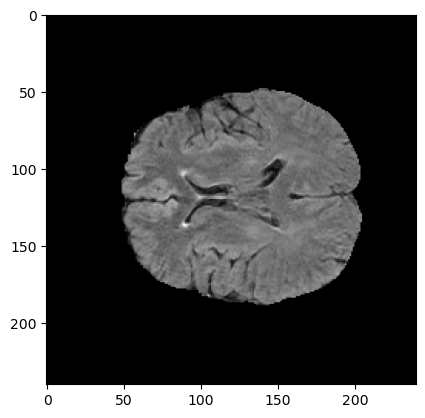

In [10]:
import nibabel as nib

def show_nii_images(nii_file_path):

    img = nib.load(nii_file_path)
    img_data = img.get_fdata()

    plt.imshow(img_data[:, :, img_data.shape[2] // 2], cmap='gray')
    plt.show()

show_nii_images("/media/licongcong/Data 1/TCGA-GBM/MRI-images/TCGA-02-0006/TCGA-02-0006_1996.08.23_flair.nii.gz")

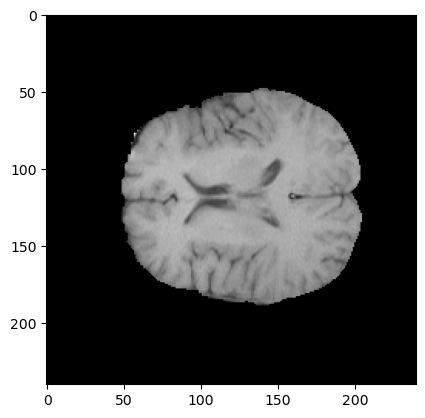

In [11]:
show_nii_images("/media/licongcong/Data 1/TCGA-GBM/MRI-images/TCGA-02-0006/TCGA-02-0006_1996.08.23_t1.nii.gz")

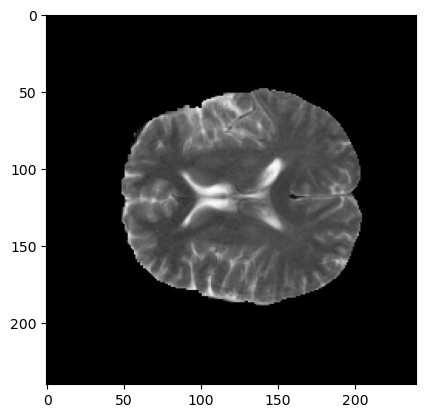

In [12]:
show_nii_images("/media/licongcong/Data 1/TCGA-GBM/MRI-images/TCGA-02-0006/TCGA-02-0006_1996.08.23_t2.nii.gz")

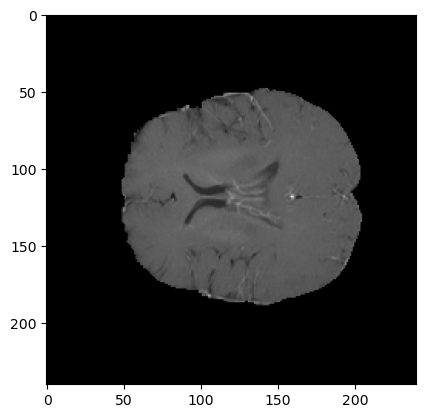

In [13]:
show_nii_images("/media/licongcong/Data 1/TCGA-GBM/MRI-images/TCGA-02-0006/TCGA-02-0006_1996.08.23_t1Gd.nii.gz")

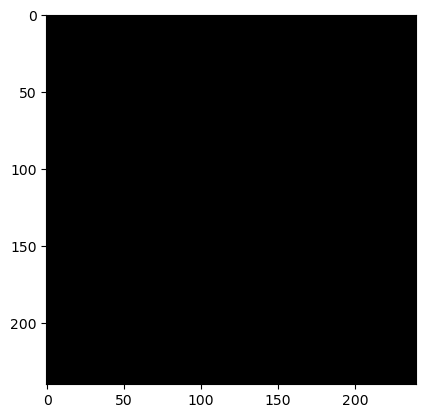

In [17]:
show_nii_images("/media/licongcong/Data 1/TCGA-GBM/MRI-images/TCGA-02-0006/TCGA-02-0006_1996.08.23_GlistrBoost_ManuallyCorrected.nii.gz")

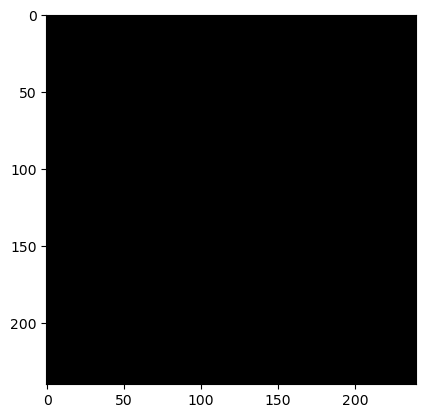

In [19]:
show_nii_images("/media/licongcong/Data 1/TCGA-GBM/MRI-images/TCGA-02-0006/TCGA-02-0006_1996.08.23_GlistrBoost.nii.gz")